Métriques sur les équipements de test :
accuracy: 0.330
balanced_accuracy: 0.330
f1_macro: 0.327
f1_weighted: 0.327

Rapport par état :
              precision    recall  f1-score   support

    Critical       0.32      0.27      0.29       679
     Healthy       0.35      0.42      0.38       684
     Warning       0.31      0.30      0.31       670

    accuracy                           0.33      2033
   macro avg       0.33      0.33      0.33      2033
weighted avg       0.33      0.33      0.33      2033

Matrice de confusion (lignes = réel, colonnes = prédit) :
          Critical  Healthy  Warning
Critical       180      267      232
Healthy        181      288      215
Warning        193      274      203

Accuracy de référence : 0.336

Importance des variables :
EngineTemp     25.659297
Vibration      25.432793
Pressure       24.811274
HealthIndex    24.096637
dtype: float64
- digital_twin_catboost.cbm : modèle final
- digital_twin_metrics.json : métriques de test
- digital_tw

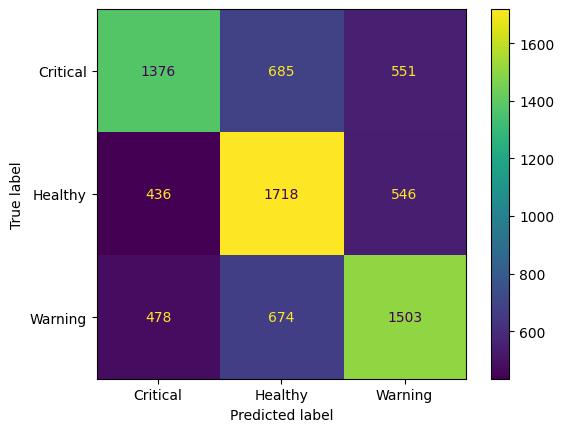

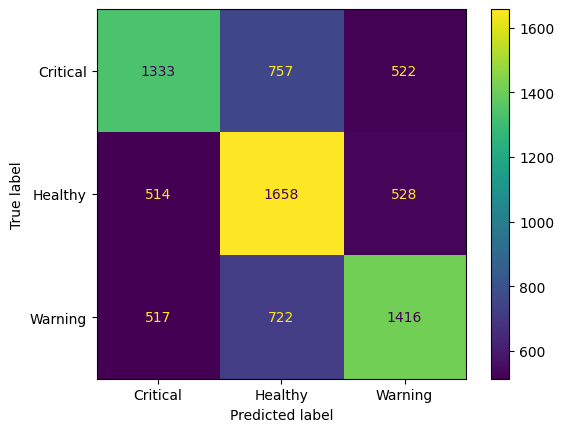

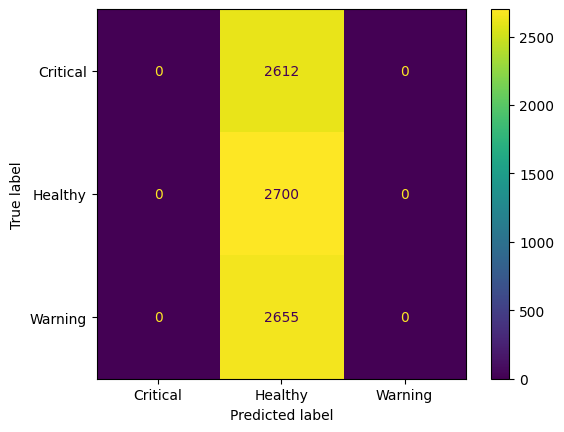

In [6]:
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,ConfusionMatrixDisplay,
)
from sklearn.model_selection import GroupShuffleSplit



FEATURES = ["HealthIndex", "EngineTemp", "Vibration", "Pressure"]
TARGET = "State"
GROUP = "Equipment"


df = pd.read_csv("digitalTwin.csv")
X = df[FEATURES]
y = df[TARGET]
groups = df[GROUP]


splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]


model_test = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    random_seed=42,
    verbose=False,
)
model_test.fit(X_train, y_train)


predictions = model_test.predict(X_test).ravel()
probabilities = model_test.predict_proba(X_test)
classes = model_test.classes_

metrics = {
    "accuracy": accuracy_score(y_test, predictions),
    "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
    "f1_macro": f1_score(y_test, predictions, average="macro"),
    "f1_weighted": f1_score(y_test, predictions, average="weighted"),
}

print("Métriques sur les équipements de test :")
for name, value in metrics.items():
    print(f"{name}: {value:.3f}")

print("\nRapport par état :")
print(classification_report(y_test, predictions, zero_division=0))

print("Matrice de confusion (lignes = réel, colonnes = prédit) :");
_=ConfusionMatrixDisplay.from_estimator(model_test,X_train,y_train);
_=ConfusionMatrixDisplay.from_estimator(model_final,X_train,y_train);
_=ConfusionMatrixDisplay.from_estimator(baseline,X_train,y_train);
print(pd.DataFrame(
    confusion_matrix(y_test, predictions, labels=classes),
    index=classes,
    columns=classes,
))


baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
print("\nAccuracy de référence :", round(accuracy_score(y_test, baseline_predictions), 3))


feature_importance = pd.Series(
    model_test.get_feature_importance(), index=FEATURES
).sort_values(ascending=False)
print("\nImportance des variables :")
print(feature_importance)
feature_importance.to_csv("digital_twin_feature_importance.csv", header=["importance"])


results = df.iloc[test_idx][[GROUP]].copy()
results["State_reel"] = y_test.to_numpy()
results["State_predit"] = predictions
results["Confiance"] = probabilities.max(axis=1)
for i, state in enumerate(classes):
    results[f"Probabilite_{state}"] = probabilities[:, i]
results.to_csv("digital_twin_test_predictions.csv", index=False)



model_final = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    random_seed=42,
    verbose=False,
)
model_final.fit(X, y)
model_final.save_model("digital_twin_catboost.cbm")

print("- digital_twin_catboost.cbm : modèle final")
print("- digital_twin_metrics.json : métriques de test")
print("- digital_twin_test_predictions.csv : prédictions et probabilités")
print("- digital_twin_feature_importance.csv : importance des variables")